# MindQuantum 编程实践进阶：量子傅里叶变换（QFT）

## 使用 MindQuantum 实现 QFT

在 MindQuantum 中导入 QFT 线路，并以 `svg` 格式查看：

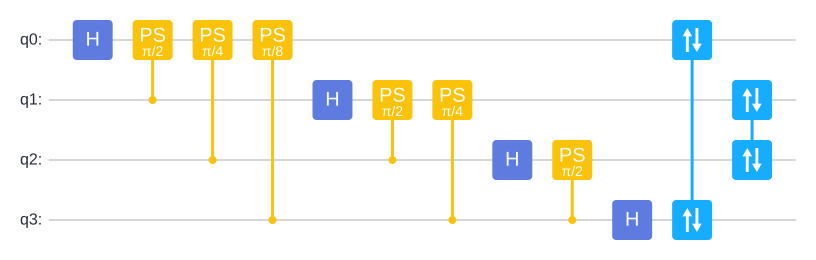

In [8]:
from mindquantum.algorithm.library import qft

circ = qft(range(4))
circ.svg()

使用量子模拟器计算 QFT 线路的末态：

In [9]:
import time
from mindquantum.simulator import Simulator
from mindquantum.algorithm.library import qft

start = time.perf_counter()
n_qubits = 8
print(f"--- 开始QFT模拟，比特数: {n_qubits} ---")

circ = qft(range(n_qubits))
sim = Simulator("mqvector", circ.n_qubits)
sim.apply_circuit(circ)
state = sim.get_qs(ket=True)

print(f"耗时: {time.perf_counter() - start:.3f}s\n")

print("\nQFT变换后的最终量子态：")
lines = state.split('\n')
print('\n'.join(lines[:16]))
print(f"... (仅显示前16项)") if len(lines) > 16 else None

--- 开始QFT模拟，比特数: 8 ---
耗时: 0.014s


QFT变换后的最终量子态：
1/16¦00000000⟩
1/16¦00000001⟩
1/16¦00000010⟩
1/16¦00000011⟩
1/16¦00000100⟩
1/16¦00000101⟩
1/16¦00000110⟩
1/16¦00000111⟩
1/16¦00001000⟩
1/16¦00001001⟩
1/16¦00001010⟩
1/16¦00001011⟩
1/16¦00001100⟩
1/16¦00001101⟩
1/16¦00001110⟩
1/16¦00001111⟩
... (仅显示前16项)


## 对比试验：使用 Numpy 实现 QFT

作为对比，我们可以尝试使用 NumPy 实现对 QFT 的模拟，看看与 MindQuantum 的实现相比有哪些差异。实现思路很直观：首先将基础量子门（H, Rk 等）定义为矩阵，然后利用张量积（kron）构建作用于整个系统的算符。

In [10]:
import time
import numpy as np
from functools import reduce

I = np.array([[1, 0], [0, 1]], dtype=np.complex128)
H = (1 / np.sqrt(2)) * np.array([[1, 1], [1, -1]], dtype=np.complex128)
X = np.array([[0, 1], [1, 0]], dtype=np.complex128)
P0 = np.array([[1, 0], [0, 0]], dtype=np.complex128)
P1 = np.array([[0, 0], [0, 1]], dtype=np.complex128)


def R(k):
    theta = 2 * np.pi / (2**k)
    return np.array([[1, 0], [0, np.exp(1j * theta)]], dtype=np.complex128)


def kron_all(ops):
    return reduce(np.kron, ops)


def apply_gate(state_vector, gate, target_qubit):
    n_qubits = int(np.log2(len(state_vector)))
    ops = [I] * n_qubits
    ops[n_qubits - 1 - target_qubit] = gate
    return kron_all(ops) @ state_vector


def apply_controlled_gate(state_vector, gate, control_qubit, target_qubit):
    n_qubits = int(np.log2(len(state_vector)))
    ops0 = [I] * n_qubits
    ops1 = [I] * n_qubits
    idx_control = n_qubits - 1 - control_qubit
    idx_target = n_qubits - 1 - target_qubit
    ops0[idx_control] = P0
    ops1[idx_control] = P1
    ops1[idx_target] = gate
    return (kron_all(ops0) + kron_all(ops1)) @ state_vector


def show_progress(step, total):
    filled = int(20 * step / total)
    bar = "#" * filled + "-" * (20 - filled)
    end = "" if step < total else "\n"
    print(f"\r量子门执行进度: [{bar}] {step}/{total}", end=end)


def qft(n_qubits):
    start = time.perf_counter()
    dim = 2**n_qubits
    state = np.zeros(dim, dtype=np.complex128)
    state[0] = 1.0
    print(f"--- 开始QFT模拟，比特数: {n_qubits} ---")
    total = n_qubits + n_qubits * (n_qubits - 1) // 2 + 3 * (n_qubits // 2)
    step = 0

    def advance():
        nonlocal step
        step += 1
        show_progress(step, total)

    for i in range(n_qubits):
        state = apply_gate(state, H, i)
        advance()
        for j in range(i + 1, n_qubits):
            state = apply_controlled_gate(state, R(j - i + 1), j, i)
            advance()
    for i in range(n_qubits // 2):
        j = n_qubits - 1 - i
        for control, target in ((i, j), (j, i), (i, j)):
            state = apply_controlled_gate(state, X, control, target)
            advance()
    print(f"耗时: {time.perf_counter() - start:.3f}s")
    return state


n_qubits = 8
final_state = qft(n_qubits)
print("\nQFT变换后的最终量子态：")
for i, amp in enumerate(final_state[:16]):
    print(f"|{bin(i)[2:].zfill(n_qubits)}> :  振幅 = {amp:+.3f}")
print(f"... (仅显示前16项)") if len(final_state) > 16 else None

--- 开始QFT模拟，比特数: 8 ---
量子门执行进度: [####################] 48/48
耗时: 0.081s

QFT变换后的最终量子态：
|00000000> :  振幅 = +0.062+0.000j
|00000001> :  振幅 = +0.062+0.000j
|00000010> :  振幅 = +0.062+0.000j
|00000011> :  振幅 = +0.062+0.000j
|00000100> :  振幅 = +0.062+0.000j
|00000101> :  振幅 = +0.062+0.000j
|00000110> :  振幅 = +0.062+0.000j
|00000111> :  振幅 = +0.062+0.000j
|00001000> :  振幅 = +0.062+0.000j
|00001001> :  振幅 = +0.062+0.000j
|00001010> :  振幅 = +0.062+0.000j
|00001011> :  振幅 = +0.062+0.000j
|00001100> :  振幅 = +0.062+0.000j
|00001101> :  振幅 = +0.062+0.000j
|00001110> :  振幅 = +0.062+0.000j
|00001111> :  振幅 = +0.062+0.000j
... (仅显示前16项)


> 可以更改量子线路的比特数 `n_qubits` ，观察不同比特规模下的运行耗时。（Numpy的部分不要超过12比特，内存占用会飙升）

可以看到，基于 Numpy 的实现与基于 MindQuantum 的实现相比：

- 使用 Numpy 手工构建需要从头实现量子计算模拟过程，代码量较大；
- 性能上则差异更加明显：随着比特数的增加，基于 Numpy 的实现会比基于 MindQuantum 的实现慢上百倍甚至上万倍；
- 如果观察内存占用情况，会发现基于 Numpy 的实现会占用巨量内存，12比特就达到 GB 级别，而 MindQuantum 在个人PC上可以模拟到28比特左右的规模。

# 挑战题——破解神秘量子门的相位（量子相位估计）

## 题目背景

假设你获得了一个神秘的单比特量子门 $U$（代码中封装为 `MysteryGate`），它的作用效果是：
$$ U|1\rangle = e^{2\pi i \varphi} |1\rangle $$
你的任务是利用 **量子相位估计算法 (QPE)**，找出这个神秘相位 $\varphi$ 的值（一个 $0$ 到 $1$ 之间的小数）。

## 任务要求

你需要构建一个标准的 QPE 线路，它包含三个步骤：
1.  **叠加 (Superposition)**：对用于估计的辅助比特施加 Hadamard 门，将目标比特翻转到 $|1\rangle$ 态。
2.  **受控幺正演化 (Controlled-U)**：对第 $i$ 个辅助比特，施加受控的 $U^{2^i}$ 操作。
3.  **逆量子傅里叶变换 (Inverse QFT)**：将相位信息转化为可测量的基态信息，并通过测量反推出 $\varphi$。

![QPE Circuit](https://mindspore-website.obs.cn-north-4.myhuaweicloud.com/website-images/r2.7.0rc1/docs/mindquantum/docs/source_zh_cn/images/quantum_phase_estimation.png)
（注：本题中 $U$ 作用在最后一个量子比特上，辅助比特为前 $n$ 个）

## 关键接口说明

1. 量子门的指数形式

    在MindQuantum中，实现 $U^{n}$ 及其受控操作非常简单：
    * **`Power(Gate, exponent)`**：返回量子门的指数形式。例如 `Power(U, 4)` 等价于 $U^4$。
    * **`.on(target, control)`**：指定目标比特和控制比特。
    * **示例**：`Power(U, n).on(i, j)` 表示以第 `j` 号比特为控制，第 `i` 号比特为目标，执行 $U^{n}$ 操作。

2. 逆量子傅里叶变换

    `qft(qubits)` 函数会生成指定比特上的量子傅里叶变换（QFT）线路。由于 QPE 需要用到 QFT 的逆操作（$QFT^\dagger$），你需要调用 `.hermitian()` 方法来获取其共轭转置线路。例如：`qft(range(4)).hermitian()`。

**请在标记为`#TODO`的位置完成代码编写，并将包裹代码的多行注释符`""" """`删除。**


In [ ]:
import numpy as np
from mindquantum.core.circuit import Circuit, UN
from mindquantum.core.gates import H, X, Power, PhaseShift, BARRIER, Measure
from mindquantum.simulator import Simulator
from mindquantum.algorithm.library import qft

# 1. 准备神秘门
true_phi = 0.625
MysteryGate = PhaseShift(2 * np.pi * true_phi)

# 2. 构建 QPE 线路

# TODO

# 3. 模拟与测量

# TODO
# result =


"""

# 4. 解析结果
# 获取出现概率最高的二进制串 (例如 '1010')
bit_string = list(result.data.keys())[0]

# QPE线路示意图中采用大端序，MinsQuantum采用的则是小端序，因此需要反转比特串顺序。
bit_string = bit_string[::-1]

# 计算估计相位: int(二进制串, 2) / 2^n
estimated_phi = int(bit_string, 2) / (2**n_qubits)

print(f"测量结果: {bit_string}")
print(f"估计相位: {estimated_phi}")

if abs(estimated_phi - true_phi) < 1e-5:
    print("🎉 恭喜！你成功破解了神秘相位！")
else:
    print("结果有误差，请检查受控门的顺序或QFT范围。")

"""